## Pipeline for Wav2Vec

In [1]:
import pandas as pd
import torchaudio
import torch
import numpy as np
import random
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
import matplotlib.pyplot as plt
import umap 
import openl3
import tensorflow as tf
import tensorflow_hub as hub

C:\Users\Felic\miniconda3\envs\fish-audio\lib\site-packages\resampy\filters.py:32: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
print(np.__version__)

2.2.6


In [3]:
df = pd.read_excel("descriptions.xlsx")
df.head(30)

,Fish sound,Filename,Begin time,End time,Low frequency (Hz),High frequency (Hz),Duration 90% (s),Centre frequency (Hz),Max power (dB) relative!,notes,category,extra notes,Unnamed: 12,Unnamed: 13
0,6.0,671633444.190702140024.wav,49.658,51.602,49.100000,109.800000,1.600000,70.300000,34.0,NaN,a,NaN,NaN,"show a spectrogram for a,b and c fish sounds"
1,9.0,1208221730.181207000246.wav,47.422,49.484,32.700000,453.200000,1.700000,187.500000,35.4,good,a,NaN,NaN,NaN
2,10.0,1208221730.181207000246.wav,66.964,67.798,14.000000,355.100000,0.600000,46.900000,43.5,NaN,a,NaN,NaN,NaN
3,11.0,1208221730.181207000246.wav,73.105,75.897,37.400000,383.100000,2.200000,152.300000,33.9,good,a,NaN,NaN,NaN
4,12.0,1208221730.181207002246.wav,8.168,9.749,39.600000,287.400000,1.200000,128.900000,35.6,good,a,NaN,NaN,NaN
5,13.0,1208221730.181207002246.wav,57.681,59.449,49.600000,317.200000,1.400000,175.800000,35.4,NaN,a,NaN,NaN,NaN
6,14.0,1208221730.181207024246.wav,45.020,46.950,52.900000,183.400000,1.600000,117.200000,31.4,good,a,NaN,NaN,NaN
7,15.0,1208221730.181207024246.wav,53.947,56.389,99.100000,252.800000,1.900000,152.300000,32.6,NaN,a,NaN,NaN,NaN
8,17.0,1208221730.181207162246.wav,47.508,50.149,21.000000,264.000000,2.100000,117.200000,36.8,NaN,a,NaN,NaN,NaN
9,18.0,1208221730.181207182246.wav,54.366,62.523,19.800000,351.900000,5.700000,105.500000,44.5,very good,a,long,NaN,NaN


In [4]:
df = df.iloc[0:20, 0:11]
# "a" = positive, everything else = negative (ignored for now)
df = df.rename(columns = {"Begin time": "start_s", "End time": "end_s"})
df["label"] = df["category"].apply(lambda x: "positive" if x == "a" else "ignore")
df.head(30)

,Fish sound,Filename,start_s,end_s,Low frequency (Hz),High frequency (Hz),Duration 90% (s),Centre frequency (Hz),Max power (dB) relative!,notes,category,label
0,6.0,671633444.190702140024.wav,49.658,51.602,49.1,109.8,1.6,70.3,34.0,NaN,a,positive
1,9.0,1208221730.181207000246.wav,47.422,49.484,32.7,453.2,1.7,187.5,35.4,good,a,positive
2,10.0,1208221730.181207000246.wav,66.964,67.798,14.0,355.1,0.6,46.9,43.5,NaN,a,positive
3,11.0,1208221730.181207000246.wav,73.105,75.897,37.4,383.1,2.2,152.3,33.9,good,a,positive
4,12.0,1208221730.181207002246.wav,8.168,9.749,39.6,287.4,1.2,128.9,35.6,good,a,positive
5,13.0,1208221730.181207002246.wav,57.681,59.449,49.6,317.2,1.4,175.8,35.4,NaN,a,positive
6,14.0,1208221730.181207024246.wav,45.020,46.950,52.9,183.4,1.6,117.2,31.4,good,a,positive
7,15.0,1208221730.181207024246.wav,53.947,56.389,99.1,252.8,1.9,152.3,32.6,NaN,a,positive
8,17.0,1208221730.181207162246.wav,47.508,50.149,21.0,264.0,2.1,117.2,36.8,NaN,a,positive
9,18.0,1208221730.181207182246.wav,54.366,62.523,19.8,351.9,5.7,105.5,44.5,very good,a,positive


In [5]:
def summarize(mat):
    # square matrix → remove diagonal
    if mat.shape[0] == mat.shape[1]:
        mask = ~np.eye(mat.shape[0], dtype=bool)
        vals = mat[mask]
    else:
        # rectangular matrix → just flatten
        vals = mat.flatten()

    return {
        "mean": float(vals.mean()),
        "std": float(vals.std()),
        "min": float(vals.min()),
        "max": float(vals.max()),
        "median": float(np.median(vals))
    }
def extract_clip(wav, sr, start_s, end_s):
    start = int(start_s * sr)
    end = int(end_s * sr)
    return wav[:, start:end]

def sample_negative_intervals(pos_intervals, file_duration, clip_length=2.0, max_tries=100):
    """
    pos_intervals: list of (start_s, end_s)
    file_duration: total duration in seconds
    clip_length: length of negative clip in seconds
    """
    for _ in range(max_tries):
        start = random.uniform(0, file_duration - clip_length)
        end = start + clip_length

        # check overlap
        overlap = any(not (end <= ps or start >= pe) for ps, pe in pos_intervals)
        if not overlap:
            return (start, end)

    return None  # if no clean region found


bundle = torchaudio.pipelines.WAV2VEC2_BASE
model = bundle.get_model().eval()

def embed_wav2vec(waveform):
    with torch.inference_mode():
        feats, _ = model.extract_features(waveform)
        emb = feats[-1].mean(dim=1)
    return emb.squeeze().cpu().numpy()


def build_pos_neg_embeddings(df, audio_dir, neg_per_file=10, neg_clip_length=2.0):
    pos_embs = []
    neg_embs = []

    for fname, group in df.groupby("Filename"):
        wav, sr = torchaudio.load(f"{audio_dir}/{fname}")
        file_duration = wav.shape[1] / sr

        # collect positive intervals
        pos_intervals = [(row.start_s, row.end_s) for _, row in group.iterrows()]

        # embed positives
        for start_s, end_s in pos_intervals:
            clip = extract_clip(wav, sr, start_s, end_s)
            pos_embs.append(embed_wav2vec(clip))

        # generate negatives
        max = neg_per_file
        a = 0
        while a < max:
            interval = sample_negative_intervals(
                pos_intervals,
                file_duration,
                clip_length=neg_clip_length
            )
            if interval is None:
                break  # no more clean space left
        
            start_s, end_s = interval
            clip = extract_clip(wav, sr, start_s, end_s)
            neg_embs.append(embed_wav2vec(clip))
            a += 1

    return np.vstack(pos_embs), np.vstack(neg_embs)

In [6]:
pos_embs, neg_embs = build_pos_neg_embeddings(df, ".")
print(pos_embs.shape, neg_embs.shape)


pos_pos_cos = cosine_similarity(pos_embs)
neg_neg_cos = cosine_similarity(neg_embs)
pos_neg_cos = cosine_similarity(pos_embs, neg_embs)

pos_pos_l2 = euclidean_distances(pos_embs)
neg_neg_l2 = euclidean_distances(neg_embs)
pos_neg_l2 = euclidean_distances(pos_embs, neg_embs)



summary = {
    "pos_pos_cos": summarize(pos_pos_cos),
    "neg_neg_cos": summarize(neg_neg_cos),
    "pos_neg_cos": summarize(pos_neg_cos),
    "pos_pos_l2": summarize(pos_pos_l2),
    "neg_neg_l2": summarize(neg_neg_l2),
    "pos_neg_l2": summarize(pos_neg_l2),
}

df_summary = pd.DataFrame(summary).T
df_summary

(20, 768) (130, 768)


,mean,std,min,max,median
pos_pos_cos,0.696208,0.276055,-0.127783,0.988245,0.783853
neg_neg_cos,0.755374,0.268495,-0.144540,0.998820,0.859788
pos_neg_cos,0.720838,0.267738,-0.145045,0.996972,0.819469
pos_pos_l2,5.929578,2.759054,1.281042,13.017605,5.502329
neg_neg_l2,5.082417,2.680208,0.383820,13.217560,4.309237
pos_neg_l2,5.609300,2.648705,0.627559,13.238610,4.940485


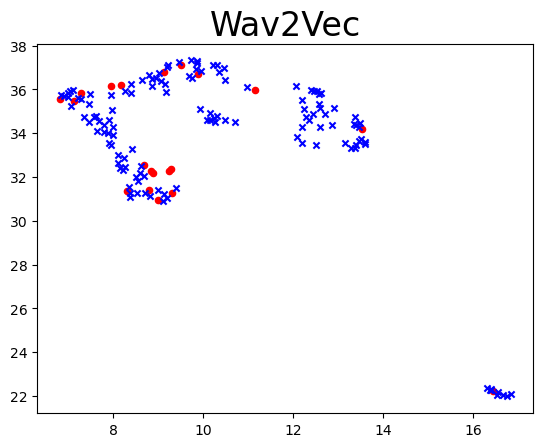

In [11]:
reducer = umap.UMAP()

pos_neg = np.vstack([pos_embs, neg_embs])

embedding = reducer.fit_transform(pos_neg)
embedding.shape

colors = ["red"] * 20 + ["blue"] * 130
markers = ["o"]  * 20 + ["x"]   * 130   # circles for pos, triangles for neg
for (x, y), c, m in zip(embedding, colors, markers):
    plt.scatter(x, y, c=c, marker=m, s=20)
    
plt.title('Wav2Vec', fontsize=24);
plt.show()

# Notes: 
* Could try to do different embedding space
* Look at sound event detection contest for ideas
* Need to look into possible options
* Later: 
* Could also do spectrograms
* Start with Matts code and go from there
* Look at downsampling the audio, filter out high frequencies using librosa (max 2000 Hz)

* Once you have spectrogram: audio spectrogram transformer

* Power law detector for whale calls (Not classifier, only filters it) - sit down with Evan to work on this next week

In [12]:
# PCA, t-sne, and umap are the three dimen reduc ones
df

,Fish sound,Filename,start_s,end_s,Low frequency (Hz),High frequency (Hz),Duration 90% (s),Centre frequency (Hz),Max power (dB) relative!,notes,category,label
0,6.0,671633444.190702140024.wav,49.658,51.602,49.1,109.8,1.6,70.3,34.0,NaN,a,positive
1,9.0,1208221730.181207000246.wav,47.422,49.484,32.7,453.2,1.7,187.5,35.4,good,a,positive
2,10.0,1208221730.181207000246.wav,66.964,67.798,14.0,355.1,0.6,46.9,43.5,NaN,a,positive
3,11.0,1208221730.181207000246.wav,73.105,75.897,37.4,383.1,2.2,152.3,33.9,good,a,positive
4,12.0,1208221730.181207002246.wav,8.168,9.749,39.6,287.4,1.2,128.9,35.6,good,a,positive
5,13.0,1208221730.181207002246.wav,57.681,59.449,49.6,317.2,1.4,175.8,35.4,NaN,a,positive
6,14.0,1208221730.181207024246.wav,45.020,46.950,52.9,183.4,1.6,117.2,31.4,good,a,positive
7,15.0,1208221730.181207024246.wav,53.947,56.389,99.1,252.8,1.9,152.3,32.6,NaN,a,positive
8,17.0,1208221730.181207162246.wav,47.508,50.149,21.0,264.0,2.1,117.2,36.8,NaN,a,positive
9,18.0,1208221730.181207182246.wav,54.366,62.523,19.8,351.9,5.7,105.5,44.5,very good,a,positive


# WavLM

In [13]:
model = torchaudio.models.wavlm_base().eval()

def embed_wavlm(waveform):
    """
    waveform: Tensor [1, T]
    returns: numpy vector [hidden_dim]
    """
    with torch.inference_mode():
        x, layer_results = model(waveform)   # unpack tuple
        emb = x.mean(dim=1)                  # mean pool over time
    return emb.squeeze().cpu().numpy()



def wavlm_build_pos_neg_embeddings(df, audio_dir, neg_per_file=10, neg_clip_length=2.0):
    pos_embs = []
    neg_embs = []

    for fname, group in df.groupby("Filename"):
        wav, sr = torchaudio.load(f"{audio_dir}/{fname}")
        file_duration = wav.shape[1] / sr

        # collect positive intervals
        pos_intervals = [(row.start_s, row.end_s) for _, row in group.iterrows()]

        # embed positives
        for start_s, end_s in pos_intervals:
            clip = extract_clip(wav, sr, start_s, end_s)
            pos_embs.append(embed_wavlm(clip))

        # generate negatives
        count = 0
        while count < neg_per_file:
            interval = sample_negative_intervals(
                pos_intervals,
                file_duration,
                clip_length=neg_clip_length
            )
            if interval is None:
                break

            start_s, end_s = interval
            clip = extract_clip(wav, sr, start_s, end_s)
            neg_embs.append(embed_wavlm(clip))
            count += 1

    return np.vstack(pos_embs), np.vstack(neg_embs)


In [14]:
lmpos_embs, lmneg_embs = wavlm_build_pos_neg_embeddings(df, ".")
print(lmpos_embs.shape, lmneg_embs.shape)


lmpos_pos_cos = cosine_similarity(lmpos_embs)
lmneg_neg_cos = cosine_similarity(lmneg_embs)
lmpos_neg_cos = cosine_similarity(lmpos_embs, lmneg_embs)

lmpos_pos_l2 = euclidean_distances(lmpos_embs)
lmneg_neg_l2 = euclidean_distances(lmneg_embs)
lmpos_neg_l2 = euclidean_distances(lmpos_embs, lmneg_embs)

summary = {
    "pos_pos_cos": summarize(lmpos_pos_cos),
    "neg_neg_cos": summarize(lmneg_neg_cos),
    "pos_neg_cos": summarize(lmpos_neg_cos),
    "pos_pos_l2": summarize(lmpos_pos_l2),
    "neg_neg_l2": summarize(lmneg_neg_l2),
    "pos_neg_l2": summarize(lmpos_neg_l2),
}

df_summary = pd.DataFrame(summary).T
df_summary

(20, 768) (130, 768)


,mean,std,min,max,median
pos_pos_cos,0.999089,0.001796,0.989176,0.999995,0.999774
neg_neg_cos,0.992221,0.041428,0.676383,1.000000,0.999988
pos_neg_cos,0.995643,0.029623,0.727603,0.999998,0.999837
pos_pos_l2,0.855940,0.814705,0.088528,4.073903,0.589687
neg_neg_l2,0.966712,3.185930,0.020440,21.119114,0.135570
pos_neg_l2,0.948625,2.315257,0.059636,19.574293,0.499862


In [25]:
reducer = umap.UMAP()

lmpos_neg = np.vstack([lmpos_embs, lmneg_embs])

lmembedding = reducer.fit_transform(lmpos_neg)
print(lmembedding.shape)
print(lmpos_embs.shape)

(150, 2)
(20, 768)


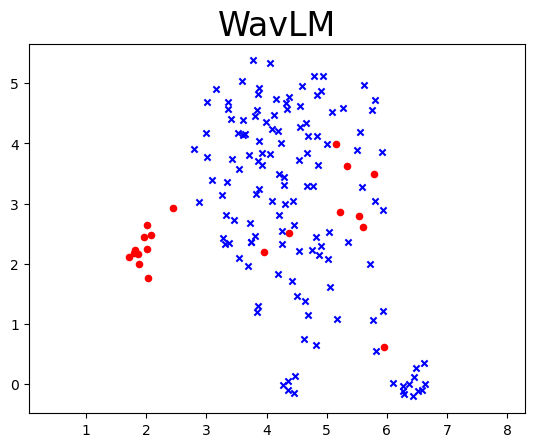

In [26]:

colors = ["red"] * 20 + ["blue"] * 130
markers = ["o"]  * 20 + ["x"]   * 130   # circles for pos, triangles for neg
for (x, y), c, m in zip(lmembedding, colors, markers):
    plt.scatter(x, y, c=c, marker=m, s=20)
    
plt.gca().set_aspect('equal', 'datalim')
plt.title('WavLM', fontsize=24);
plt.show()

# Open L3

In [27]:
openl3_model = openl3.models.load_audio_embedding_model(
    input_repr="mel256",      # recommended for ecoacoustics
    content_type="env",       # environmental model
    embedding_size=6144        # or 6144 for large model
)


def embed_openl3(waveform, sr):
    """
    waveform: Tensor [1, T]
    sr: sample rate
    returns: numpy vector [embedding_dim]
    """
    # Convert to numpy float32, mono
    audio_np = waveform.squeeze().cpu().numpy().astype(np.float32)

    emb, ts = openl3.get_audio_embedding(
        audio_np,
        sr,
        model=openl3_model,
        hop_size=0.1,        # default
        center=True,
        verbose=False
    )

    # emb shape: (num_frames, embedding_dim)
    return emb.mean(axis=0)   # mean-pool over time

def openl3_build_pos_neg_embeddings(df, audio_dir, neg_per_file=10, neg_clip_length=2.0):
    pos_embs = []
    neg_embs = []

    for fname, group in df.groupby("Filename"):
        wav, sr = torchaudio.load(f"{audio_dir}/{fname}")
        file_duration = wav.shape[1] / sr

        # collect positive intervals
        pos_intervals = [(row.start_s, row.end_s) for _, row in group.iterrows()]

        # embed positives
        for start_s, end_s in pos_intervals:
            clip = extract_clip(wav, sr, start_s, end_s)
            pos_embs.append(embed_openl3(clip, sr))

        # generate negatives
        count = 0
        while count < neg_per_file:
            interval = sample_negative_intervals(
                pos_intervals,
                file_duration,
                clip_length=neg_clip_length
            )
            if interval is None:
                break

            start_s, end_s = interval
            clip = extract_clip(wav, sr, start_s, end_s)
            neg_embs.append(embed_openl3(clip, sr))
            count += 1

    return np.vstack(pos_embs), np.vstack(neg_embs)



In [28]:
openpos_embs, openneg_embs = openl3_build_pos_neg_embeddings(df, ".")
print(openpos_embs.shape, openneg_embs.shape)


openpos_pos_cos = cosine_similarity(openpos_embs)
openneg_neg_cos = cosine_similarity(openneg_embs)
openpos_neg_cos = cosine_similarity(openpos_embs, openneg_embs)

openpos_pos_l2 = euclidean_distances(openpos_embs)
openneg_neg_l2 = euclidean_distances(openneg_embs)
openpos_neg_l2 = euclidean_distances(openpos_embs, openneg_embs)

summary = {
    "pos_pos_cos": summarize(openpos_pos_cos),
    "neg_neg_cos": summarize(openneg_neg_cos),
    "pos_neg_cos": summarize(openpos_neg_cos),
    "pos_pos_l2": summarize(openpos_pos_l2),
    "neg_neg_l2": summarize(openneg_neg_l2),
    "pos_neg_l2": summarize(openpos_neg_l2),
}

df_summary = pd.DataFrame(summary).T
df_summary

C:\Users\Felic\miniconda3\envs\fish-audio\lib\site-packages\openl3\core.py:82: OpenL3Warning: Duration of provided audio is shorter than window size (1 second). Audio will be padded.
  warnings.warn('Duration of provided audio is shorter than window size (1 second). Audio will be padded.',


(20, 6144) (130, 6144)


,mean,std,min,max,median
pos_pos_cos,0.990168,0.006300,0.969618,0.998002,0.991810
neg_neg_cos,0.988650,0.012824,0.914586,0.999745,0.992612
pos_neg_cos,0.988866,0.009810,0.921409,0.998035,0.991665
pos_pos_l2,15.658614,4.976284,7.390427,28.882833,15.010012
neg_neg_l2,16.119576,8.207491,2.649996,53.904575,14.134109
pos_neg_l2,16.480303,6.479420,7.256333,52.018330,15.086689


In [29]:
reducer = umap.UMAP()

openpos_neg = np.vstack([openpos_embs, openneg_embs])

openembedding = reducer.fit_transform(openpos_neg)
print(openpos_embs.shape)
print(openneg_embs.shape)

(20, 6144)
(130, 6144)


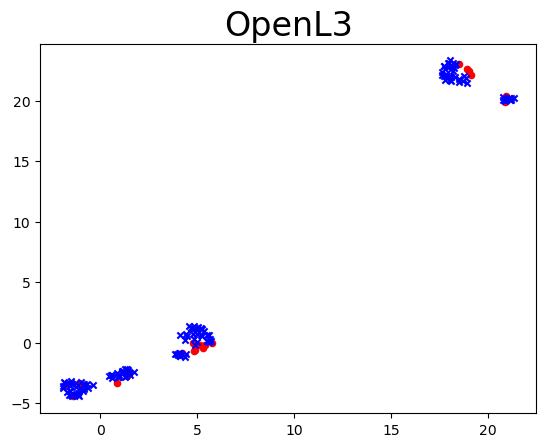

In [30]:
colors = ["red"] * 20 + ["blue"] * 130
markers = ["o"]  * 20 + ["x"]   * 130   # circles for pos, triangles for neg
for (x, y), c, m in zip(openembedding, colors, markers):
    plt.scatter(x, y, c=c, marker=m, s=20)

plt.title('OpenL3', fontsize=24);
plt.show()

# YAMNet

In [31]:
import tensorflow as tf
import tensorflow_hub as hub

yamnet_model = hub.KerasLayer("https://tfhub.dev/google/yamnet/1", trainable=False)
yamnet_sample_rate = 16000



resampler_cache = {}

def get_resampler(sr):
    if sr not in resampler_cache:
        resampler_cache[sr] = torchaudio.transforms.Resample(sr, yamnet_sample_rate)
    return resampler_cache[sr]


def embed_yamnet_tf(waveform, sr):
    # Resample if needed
    if sr != yamnet_sample_rate:
        resampler = get_resampler(sr)
        waveform = resampler(waveform)

    # Convert to numpy float32
    audio_np = waveform.squeeze().cpu().numpy().astype(np.float32)

    # Run YAMNet
    scores, embeddings, spectrogram = yamnet_model(audio_np)

    # embeddings: [frames, 1024]
    emb = embeddings.numpy().mean(axis=0)
    return emb


def yamnet_build_pos_neg_embeddings(df, audio_dir, neg_per_file=10, neg_clip_length=2.0):
    pos_embs = []
    neg_embs = []

    for fname, group in df.groupby("Filename"):
        wav, sr = torchaudio.load(f"{audio_dir}/{fname}")
        file_duration = wav.shape[1] / sr

        pos_intervals = [(row.start_s, row.end_s) for _, row in group.iterrows()]

        # positives
        for start_s, end_s in pos_intervals:
            clip = extract_clip(wav, sr, start_s, end_s)
            pos_embs.append(embed_yamnet_tf(clip, sr))

        # negatives
        count = 0
        while count < neg_per_file:
            interval = sample_negative_intervals(
                pos_intervals,
                file_duration,
                clip_length=neg_clip_length
            )
            if interval is None:
                break

            start_s, end_s = interval
            clip = extract_clip(wav, sr, start_s, end_s)
            neg_embs.append(embed_yamnet_tf(clip, sr))
            count += 1

    return np.vstack(pos_embs), np.vstack(neg_embs)



In [32]:
yampos_embs, yamneg_embs = yamnet_build_pos_neg_embeddings(df, ".")
print(yampos_embs.shape, yamneg_embs.shape)


yampos_pos_cos = cosine_similarity(yampos_embs)
yamneg_neg_cos = cosine_similarity(yamneg_embs)
yampos_neg_cos = cosine_similarity(yampos_embs, yamneg_embs)

yampos_pos_l2 = euclidean_distances(openpos_embs)
yamneg_neg_l2 = euclidean_distances(openneg_embs)
yampos_neg_l2 = euclidean_distances(openpos_embs, openneg_embs)

summary = {
    "pos_pos_cos": summarize(yampos_pos_cos),
    "neg_neg_cos": summarize(yamneg_neg_cos),
    "pos_neg_cos": summarize(yampos_neg_cos),
    "pos_pos_l2": summarize(yampos_pos_l2),
    "neg_neg_l2": summarize(yamneg_neg_l2),
    "pos_neg_l2": summarize(yampos_neg_l2),
}

df_summary = pd.DataFrame(summary).T
df_summary

(20, 1024) (130, 1024)


,mean,std,min,max,median
pos_pos_cos,0.980403,0.036852,0.846335,0.999497,0.995777
neg_neg_cos,0.978774,0.116383,0.040007,0.999992,0.996239
pos_neg_cos,0.979683,0.085624,0.035245,0.999946,0.996033
pos_pos_l2,15.658614,4.976284,7.390427,28.882833,15.010012
neg_neg_l2,16.119576,8.207491,2.649996,53.904575,14.134109
pos_neg_l2,16.480303,6.479420,7.256333,52.018330,15.086689


In [33]:
reducer = umap.UMAP()

yampos_neg = np.vstack([yampos_embs, yamneg_embs])

yamembedding = reducer.fit_transform(yampos_neg)
print(yamembedding.shape)
print(yampos_embs.shape)

(150, 2)
(20, 1024)


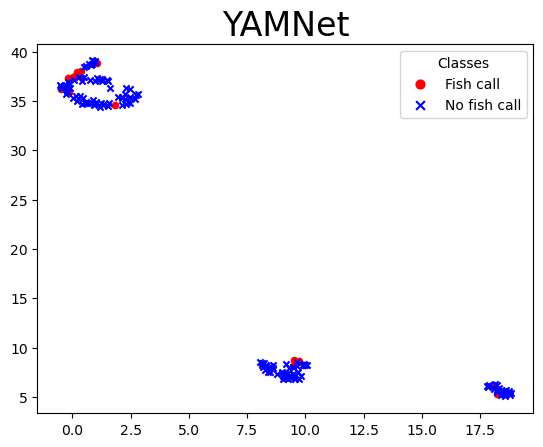

In [35]:

colors = ["red"] * 20 + ["blue"] * 130
markers = ["o"]  * 20 + ["x"]   * 130   # circles for pos, triangles for neg
for (x, y), c, m in zip(yamembedding, colors, markers):
    plt.scatter(x, y, c=c, marker=m, s=20)
fish_handle = plt.scatter([], [], c="red", marker="o", s=40, label="Fish call")
no_fish_handle = plt.scatter([], [], c="blue", marker="x", s=40, label="No fish call")

plt.legend(handles=[fish_handle, no_fish_handle], loc="upper right", title="Classes")
plt.title('YAMNet', fontsize=24);
plt.show()